<a href="https://colab.research.google.com/github/Kavya-0228/-CUSTOMER-CHURN/blob/main/DS_sat_2_R2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

air_quality = pd.read_csv('/content/air_quality.csv')
stations = pd.read_csv('/content/stations.csv')
weather = pd.read_csv('/content/weather.csv')
traffic = pd.read_csv('/content/traffic.csv')
calendar = pd.read_csv('/content/calendar.csv')

print("All 5 CSV files loaded successfully!")


All 5 CSV files loaded successfully!


In [3]:

datasets = {
    "Air Quality": air_quality,
    "Stations": stations,
    "Weather": weather,
    "Traffic": traffic,
    "Calendar": calendar
}

for name, df in datasets.items():
    print("\n", name)
    print("Shape:", df.shape)
    print(df.head())



 Air Quality
Shape: (1009, 6)
             timestamp  station  PM2.5  PM10   NO2   AQI
0  2025-01-01 00:00:00  Central   40.0  57.8   9.8  42.2
1  2025-01-01 01:00:00  Central   31.0  38.1  19.7  39.3
2  2025-01-01 02:00:00  Central   52.3  67.2  18.7  60.7
3  2025-01-01 03:00:00  Central   26.0  41.5   6.0  34.2
4  2025-01-01 04:00:00  Central   55.4  82.3  18.9  77.4

 Stations
Shape: (3, 3)
       station          location land_use_type
0      Central       City Centre    Commercial
1   Industrial   Industrial Zone    Industrial
2  Residential  Residential Area   Residential

 Weather
Shape: (336, 5)
             timestamp  wind  temperature  humidity  rain
0  2025-01-01 00:00:00  10.9         25.7      56.4   0.0
1  2025-01-01 01:00:00   6.9         27.8      49.2   0.0
2  2025-01-01 02:00:00  12.3         29.6      75.0   0.0
3  2025-01-01 03:00:00  12.8         28.7      69.2   0.0
4  2025-01-01 04:00:00   4.1         23.0      93.6   0.0

 Traffic
Shape: (336, 3)
             t

In [4]:

for name, df in datasets.items():
    print("\n---", name, "---")
    print(df.info())
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())



--- Air Quality ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1009 entries, 0 to 1008
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  1009 non-null   object 
 1   station    1009 non-null   object 
 2   PM2.5      1001 non-null   float64
 3   PM10       1001 non-null   float64
 4   NO2        1001 non-null   float64
 5   AQI        1001 non-null   float64
dtypes: float64(4), object(2)
memory usage: 47.4+ KB
None

Missing values:
timestamp    0
station      0
PM2.5        8
PM10         8
NO2          8
AQI          8
dtype: int64

Duplicate rows: 1

--- Stations ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   station        3 non-null      object
 1   location       3 non-null      object
 2   land_use_type  3 non-null      object
dtypes: object(3)
memor

In [5]:

for df in [air_quality, weather, traffic, calendar]:
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

print("Timestamp conversion completed!")
print(air_quality.dtypes)


Timestamp conversion completed!
timestamp    datetime64[ns]
station              object
PM2.5               float64
PM10                float64
NO2                 float64
AQI                 float64
dtype: object


In [6]:

air_quality["station"] = (
    air_quality["station"]
    .astype("string")
    .str.strip()
    .str.title()
)

stations["station"] = (
    stations["station"]
    .astype("string")
    .str.strip()
    .str.title()
)

print(air_quality["station"].unique())


<StringArray>
['Central', 'Industrial', 'Residential']
Length: 3, dtype: string


In [7]:

print("Duplicates before cleaning:",
      air_quality.duplicated().sum())

air_quality = air_quality.drop_duplicates().copy()

print("Duplicates after cleaning:",
      air_quality.duplicated().sum())


Duplicates before cleaning: 1
Duplicates after cleaning: 0


In [8]:

print("Air Quality Missing Values:")
print(air_quality.isnull().sum())

print("\nWeather Missing Values:")
print(weather.isnull().sum())

print("\nTraffic Missing Values:")
print(traffic.isnull().sum())


Air Quality Missing Values:
timestamp    0
station      0
PM2.5        8
PM10         8
NO2          8
AQI          8
dtype: int64

Weather Missing Values:
timestamp      0
wind           5
temperature    0
humidity       5
rain           0
dtype: int64

Traffic Missing Values:
timestamp         0
traffic_volume    4
peak_flag         0
dtype: int64


In [9]:

pollution_cols = ["PM2.5", "PM10", "NO2", "AQI"]

for col in pollution_cols:
    air_quality[col] = air_quality[col].fillna(
        air_quality[col].median()
    )

weather_cols = ["wind", "temperature", "humidity", "rain"]

for col in weather_cols:
    weather[col] = weather[col].fillna(
        weather[col].median()
    )

traffic["traffic_volume"] = traffic["traffic_volume"].fillna(
    traffic["traffic_volume"].median()
)

print("Missing numeric values handled!")


Missing numeric values handled!


In [10]:

for col in ["PM2.5", "PM10", "NO2", "AQI"]:
    Q1 = air_quality[col].quantile(0.25)
    Q3 = air_quality[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = air_quality[
        (air_quality[col] < lower) |
        (air_quality[col] > upper)
    ]

    print(col, "- Possible outliers:", len(outliers))


PM2.5 - Possible outliers: 1
PM10 - Possible outliers: 0
NO2 - Possible outliers: 1
AQI - Possible outliers: 0


In [11]:

for name, df in {
    "Air Quality": air_quality,
    "Weather": weather,
    "Traffic": traffic,
    "Calendar": calendar
}.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())



 Air Quality
Missing values: 0
Duplicate rows: 0

 Weather
Missing values: 0
Duplicate rows: 0

 Traffic
Missing values: 0
Duplicate rows: 0

 Calendar
Missing values: 0
Duplicate rows: 0


In [12]:

# Merge air quality with station information
merged_df = air_quality.merge(
    stations,
    on="station",
    how="left"
)

# Merge weather data
merged_df = merged_df.merge(
    weather,
    on="timestamp",
    how="left"
)

# Merge traffic data
merged_df = merged_df.merge(
    traffic,
    on="timestamp",
    how="left"
)

# Merge calendar data
merged_df = merged_df.merge(
    calendar,
    on="timestamp",
    how="left"
)

print("All datasets merged successfully!")
print("Shape:", merged_df.shape)
print(merged_df.head())


All datasets merged successfully!
Shape: (1008, 17)
            timestamp  station  PM2.5  PM10   NO2   AQI     location  \
0 2025-01-01 00:00:00  Central   40.0  57.8   9.8  42.2  City Centre   
1 2025-01-01 01:00:00  Central   31.0  38.1  19.7  39.3  City Centre   
2 2025-01-01 02:00:00  Central   52.3  67.2  18.7  60.7  City Centre   
3 2025-01-01 03:00:00  Central   26.0  41.5   6.0  34.2  City Centre   
4 2025-01-01 04:00:00  Central   55.4  82.3  18.9  77.4  City Centre   

  land_use_type  wind  temperature  humidity  rain  traffic_volume peak_flag  \
0    Commercial  10.9         25.7      56.4   0.0           215.0        No   
1    Commercial   6.9         27.8      49.2   0.0           208.0        No   
2    Commercial  12.3         29.6      75.0   0.0           245.0        No   
3    Commercial  12.8         28.7      69.2   0.0           161.0        No   
4    Commercial   4.1         23.0      93.6   0.0           235.0        No   

     weekday holiday  season  
0  

In [13]:

print("Columns:")
print(merged_df.columns.tolist())

print("\nDataset information:")
merged_df.info()

print("\nMissing values:")
print(merged_df.isnull().sum())


Columns:
['timestamp', 'station', 'PM2.5', 'PM10', 'NO2', 'AQI', 'location', 'land_use_type', 'wind', 'temperature', 'humidity', 'rain', 'traffic_volume', 'peak_flag', 'weekday', 'holiday', 'season']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       1008 non-null   datetime64[ns]
 1   station         1008 non-null   string        
 2   PM2.5           1008 non-null   float64       
 3   PM10            1008 non-null   float64       
 4   NO2             1008 non-null   float64       
 5   AQI             1008 non-null   float64       
 6   location        1008 non-null   object        
 7   land_use_type   1008 non-null   object        
 8   wind            1008 non-null   float64       
 9   temperature     1008 non-null   float64       
 10  humidity        1008 non-null   float64   

In [14]:

# Extract time-based features
merged_df["hour"] = merged_df["timestamp"].dt.hour
merged_df["day"] = merged_df["timestamp"].dt.day
merged_df["month"] = merged_df["timestamp"].dt.month

# Create a time-of-day feature
def get_period(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

merged_df["time_period"] = merged_df["hour"].apply(get_period)

# Create a high-pollution indicator for analysis
median_aqi = merged_df["AQI"].median()
merged_df["high_aqi_flag"] = (
    merged_df["AQI"] > median_aqi
).astype(int)

print(merged_df[
    ["timestamp", "hour", "time_period",
     "AQI", "high_aqi_flag"]
].head())


            timestamp  hour time_period   AQI  high_aqi_flag
0 2025-01-01 00:00:00     0       Night  42.2              0
1 2025-01-01 01:00:00     1       Night  39.3              0
2 2025-01-01 02:00:00     2       Night  60.7              1
3 2025-01-01 03:00:00     3       Night  34.2              0
4 2025-01-01 04:00:00     4       Night  77.4              1


In [15]:

merged_df.to_csv(
    "/content/cleaned_air_quality.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [16]:

from google.colab import files
files.download("/content/cleaned_air_quality.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

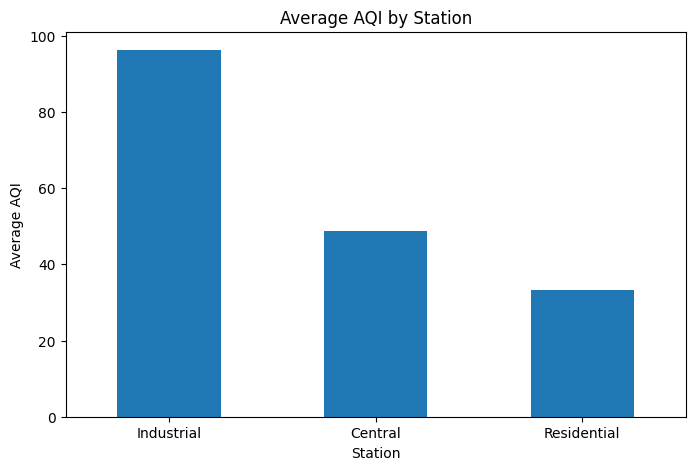

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

station_aqi = merged_df.groupby(
    "station"
)["AQI"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
station_aqi.plot(kind="bar")
plt.title("Average AQI by Station")
plt.xlabel("Station")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.show()


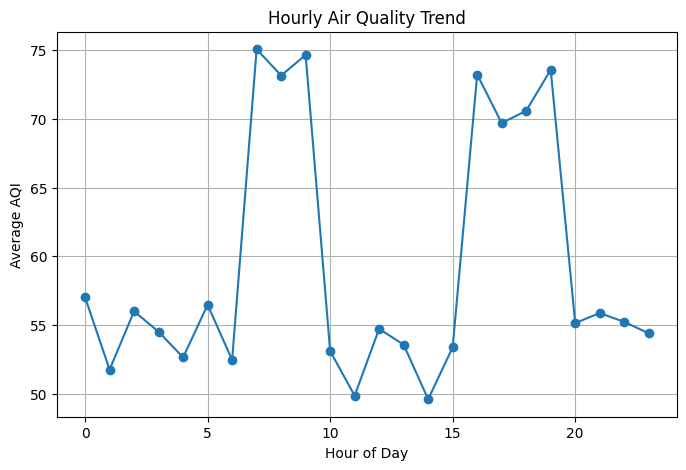

In [18]:

hourly_aqi = merged_df.groupby(
    "hour"
)["AQI"].mean()

plt.figure(figsize=(8, 5))
hourly_aqi.plot(kind="line", marker="o")
plt.title("Hourly Air Quality Trend")
plt.xlabel("Hour of Day")
plt.ylabel("Average AQI")
plt.grid(True)
plt.show()


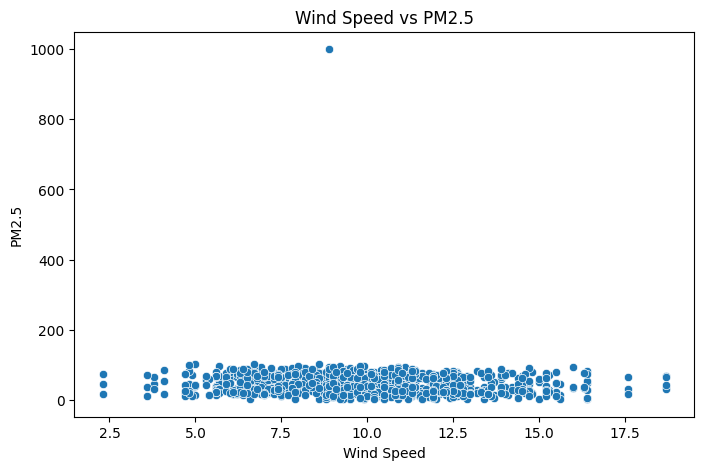

In [19]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=merged_df,
    x="wind",
    y="PM2.5"
)
plt.title("Wind Speed vs PM2.5")
plt.xlabel("Wind Speed")
plt.ylabel("PM2.5")
plt.show()


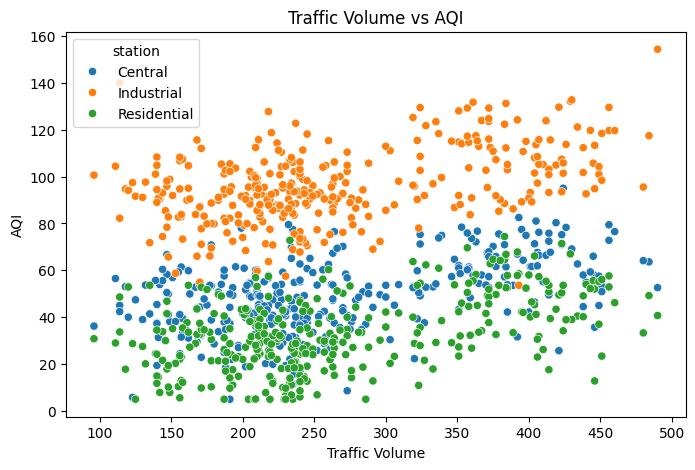

In [20]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=merged_df,
    x="traffic_volume",
    y="AQI",
    hue="station"
)
plt.title("Traffic Volume vs AQI")
plt.xlabel("Traffic Volume")
plt.ylabel("AQI")
plt.show()


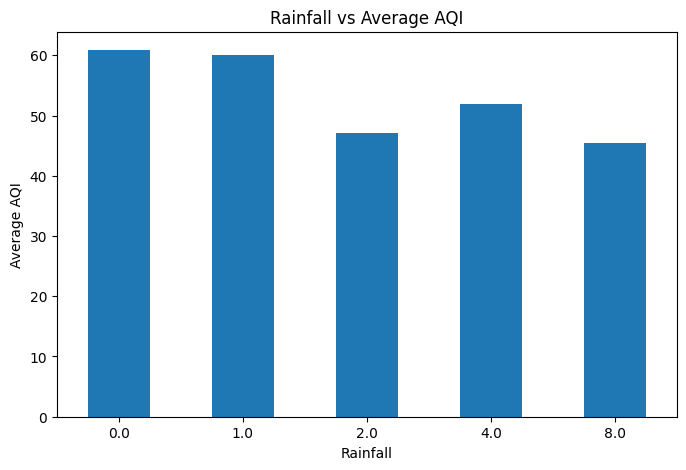

rain
0.0    60.884722
1.0    60.068519
2.0    47.038889
4.0    51.986667
8.0    45.480952
Name: AQI, dtype: float64


In [21]:

rain_aqi = merged_df.groupby("rain")["AQI"].mean()

plt.figure(figsize=(8, 5))
rain_aqi.plot(kind="bar")
plt.title("Rainfall vs Average AQI")
plt.xlabel("Rainfall")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.show()

print(rain_aqi)


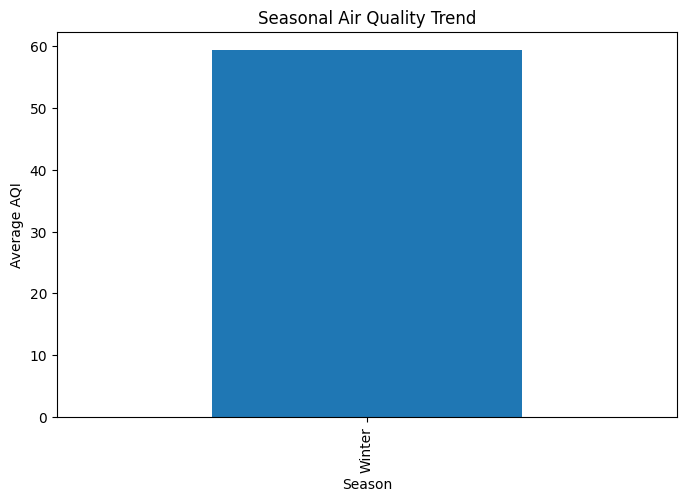

season
Winter    59.396131
Name: AQI, dtype: float64


In [22]:

season_aqi = merged_df.groupby("season")["AQI"].mean()

plt.figure(figsize=(8, 5))
season_aqi.plot(kind="bar")
plt.title("Seasonal Air Quality Trend")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.show()

print(season_aqi)


In [23]:

encoded_df = pd.get_dummies(
    merged_df,
    columns=["station", "land_use_type", "peak_flag",
             "weekday", "holiday", "season", "time_period"],
    dtype=int
)

print(encoded_df.head())
print("Encoded shape:", encoded_df.shape)


            timestamp  PM2.5  PM10   NO2   AQI     location  wind  \
0 2025-01-01 00:00:00   40.0  57.8   9.8  42.2  City Centre  10.9   
1 2025-01-01 01:00:00   31.0  38.1  19.7  39.3  City Centre   6.9   
2 2025-01-01 02:00:00   52.3  67.2  18.7  60.7  City Centre  12.3   
3 2025-01-01 03:00:00   26.0  41.5   6.0  34.2  City Centre  12.8   
4 2025-01-01 04:00:00   55.4  82.3  18.9  77.4  City Centre   4.1   

   temperature  humidity  rain  ...  weekday_Thursday  weekday_Tuesday  \
0         25.7      56.4   0.0  ...                 0                0   
1         27.8      49.2   0.0  ...                 0                0   
2         29.6      75.0   0.0  ...                 0                0   
3         28.7      69.2   0.0  ...                 0                0   
4         23.0      93.6   0.0  ...                 0                0   

   weekday_Wednesday  holiday_No  holiday_Yes  season_Winter  \
0                  1           0            1              1   
1           

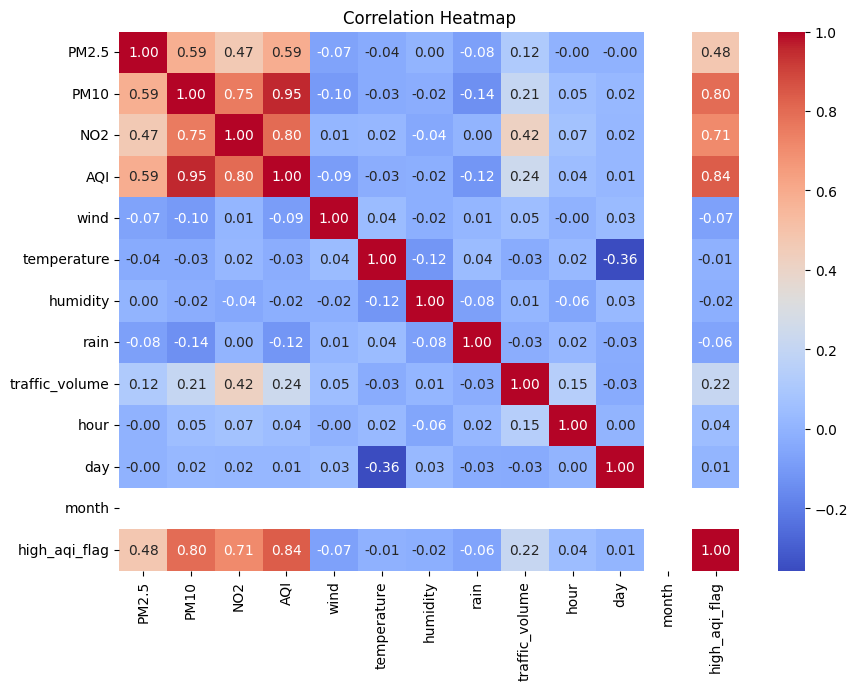

Correlation with AQI:
AQI               1.000000
PM10              0.953405
high_aqi_flag     0.836355
NO2               0.799121
PM2.5             0.587791
traffic_volume    0.241872
hour              0.042110
day               0.014603
humidity         -0.018165
temperature      -0.025090
wind             -0.086613
rain             -0.117930
month                  NaN
Name: AQI, dtype: float64


In [24]:

numeric_df = merged_df.select_dtypes(
    include=["number"]
)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with AQI:")
print(correlation["AQI"].sort_values(ascending=False))


In [25]:

merged_df.to_csv(
    "/content/cleaned_air_quality.csv",
    index=False
)

print("Final cleaned dataset saved!")
print("Rows and columns:", merged_df.shape)


Final cleaned dataset saved!
Rows and columns: (1008, 22)
